# 03.5 — Equidade, Fairness e Drift Temporal
**Depende de:** 03.3 executado antes (artefatos em out/artifacts/)
**Salva em:** out/03.5_equidade/

In [1]:
from __future__ import annotations

import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "en"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        "auroc_lbl":           "AUROC",
        "subgrupo_title":      "AUROC por Subgrupo CID — Teste",
        "faixa_auroc_title":   "AUROC por Faixa Etária",
        "faixa_sens_title":    "Sensibilidade @0.30",
        "faixa_sens_ylabel":   "Sensibilidade por Faixa Etária",
        "faixa_ppv_title":     "PPV @0.30",
        "faixa_ppv_ylabel":    "PPV por Faixa Etária",
        "faixa_suptitle_fmt":  "Análise de Fairness — {nome} | Retorno 30d",
        "drift_lbl_auroc":     "AUROC",
        "drift_lbl_sens":      "Sens@Youden",
        "drift_lbl_spec":      "Spec@Youden",
        "drift_xlabel":        "Ano",
        "drift_ylabel":        "Métrica",
        "drift_suptitle_fmt":  "Fairness por Ano — {nome} | Retorno 30d",
        "tipo_auroc_title":    "AUROC por Tipo Atendimento",
        "tipo_sens_ylabel":    "Sens @0.30",
        "tipo_sens_title":     "Sensibilidade por Tipo",
        "tipo_ppv_ylabel":     "PPV @0.30",
        "tipo_ppv_title":      "PPV por Tipo",
        "tipo_suptitle_fmt":   "Fairness por Tipo de Atendimento — {nome}",
        "par_auroc_title":     "AUROC por Paridade",
        "par_sens_ylabel":     "Sens @0.30",
        "par_sens_title":      "Sensibilidade por Paridade",
        "par_spec_ylabel":     "Spec @0.30",
        "par_spec_title":      "Especificidade por Paridade",
        "par_suptitle_fmt":    "Fairness por Paridade — {nome}",
        "lc_train_lbl":        "Treino (CV)",
        "lc_valid_lbl":        "Validação (CV)",
        "lc_xlabel":           "Tamanho do Conjunto de Treino (N amostras)",
        "lc_ylabel":           "AUROC",
        "lc_title_fmt":        "Curva de Aprendizado — {nome}",
        "temporal_xlabel":     "Ano",
        "temporal_ylabel":     "AUROC",
        "temporal_title_fmt":  "Drift Temporal — AUROC por Ano ({nome})",
        "raca_auroc_title":    "AUROC por Raça/Etnia",
        "raca_prev_lbl_fmt":   "Média ({pct:.1f}%)",
        "raca_prev_title":     "Prevalência retorno 30d (%)",
        "raca_prev_ylabel":    "Prevalência por Raça",
        "raca_sens_ylabel":    "Sensibilidade @0.30",
        "raca_sens_title":     "Sensibilidade por Raça",
        "raca_suptitle_fmt":   "Fairness por Raça/Etnia — {nome} | Retorno 30d",
    },
    "en": {
        "auroc_lbl":           "AUROC",
        "subgrupo_title":      "AUROC by ICD-10 Subgroup — Test Set",
        "faixa_auroc_title":   "AUROC by Age Group",
        "faixa_sens_title":    "Sensitivity @0.30",
        "faixa_sens_ylabel":   "Sensitivity by Age Group",
        "faixa_ppv_title":     "PPV @0.30",
        "faixa_ppv_ylabel":    "PPV by Age Group",
        "faixa_suptitle_fmt":  "Fairness Analysis — {nome} | 30-day Return",
        "drift_lbl_auroc":     "AUROC",
        "drift_lbl_sens":      "Sens@Youden",
        "drift_lbl_spec":      "Spec@Youden",
        "drift_xlabel":        "Year",
        "drift_ylabel":        "Metric",
        "drift_suptitle_fmt":  "Fairness by Year — {nome} | 30-day Return",
        "tipo_auroc_title":    "AUROC by Attendance Type",
        "tipo_sens_ylabel":    "Sens @0.30",
        "tipo_sens_title":     "Sensitivity by Type",
        "tipo_ppv_ylabel":     "PPV @0.30",
        "tipo_ppv_title":      "PPV by Type",
        "tipo_suptitle_fmt":   "Fairness by Attendance Type — {nome}",
        "par_auroc_title":     "AUROC by Parity",
        "par_sens_ylabel":     "Sens @0.30",
        "par_sens_title":      "Sensitivity by Parity",
        "par_spec_ylabel":     "Spec @0.30",
        "par_spec_title":      "Specificity by Parity",
        "par_suptitle_fmt":    "Fairness by Parity — {nome}",
        "lc_train_lbl":        "Training (CV)",
        "lc_valid_lbl":        "Validation (CV)",
        "lc_xlabel":           "Training Set Size (N samples)",
        "lc_ylabel":           "AUROC",
        "lc_title_fmt":        "Learning Curve — {nome}",
        "temporal_xlabel":     "Year",
        "temporal_ylabel":     "AUROC",
        "temporal_title_fmt":  "Temporal Drift — AUROC by Year ({nome})",
        "raca_auroc_title":    "AUROC by Race/Ethnicity",
        "raca_prev_lbl_fmt":   "Mean ({pct:.1f}%)",
        "raca_prev_title":     "30-day return prevalence (%)",
        "raca_prev_ylabel":    "Prevalence by Race",
        "raca_sens_ylabel":    "Sensitivity @0.30",
        "raca_sens_title":     "Sensitivity by Race",
        "raca_suptitle_fmt":   "Fairness by Race/Ethnicity — {nome} | 30-day Return",
    },
}
T = _T[LANG]

# Paths
ROOT     = Path("..").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR  = ROOT / "out" / "03.5_equidade"
PLOT_DIR = OUT_DIR / "plots"
ART_DIR  = ROOT / "out" / "artifacts"   # shared state between sub-files

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
def segmento_cid(cid):
    if pd.isna(cid): return "SEM_CID"
    c = str(cid).upper()
    if c[:3] in [f"O{i:02d}" for i in range(10, 17)]:  return "HIPERTENSIVOS"
    if c[:3] in ["O24"]:                                 return "DIABETES_GEST"
    if c[:3] in ["O60", "O42", "O47"]:                  return "PARTO_PREMATURO"
    if c[:2] in ["O2", "O3"] or c[:3] in ["O44","O45","O46"]: return "HEMORRAGIA"
    if c[:3] in ["O98"]:                                 return "INFECCAO"
    if c[:3] in ["O99"]:                                 return "COMORBIDADES"
    if c[0] == "P":                                      return "RISCO_NEONATAL"
    if c[0] == "O":                                      return "OUTROS_OBST"
    if c[:2] == "Z3":                                    return "PRE_NATAL"
    return "OUTROS"




## Carregar Artefatos

In [3]:
with open(ART_DIR / "splits.pkl", "rb") as f:
    _splits = pickle.load(f)

df_train  = _splits["df_train"]
df_valid  = _splits["df_valid"]
df_test   = _splits["df_test"]
y_train   = _splits["y_train"]
y_valid   = _splits["y_valid"]
y_test    = _splits["y_test"]
X_train_t = _splits["X_train_t"]
X_valid_t = _splits["X_valid_t"]
X_test_t  = _splits["X_test_t"]
X_train   = _splits["X_train"]
X_valid   = _splits["X_valid"]
X_test    = _splits["X_test"]

with open(ART_DIR / "features.json", "r", encoding="utf-8") as f:
    _feat = json.load(f)
FEATURES         = _feat["FEATURES"]
TARGET_PRINCIPAL = _feat["TARGET_PRINCIPAL"]
THRESHOLD        = _feat["THRESHOLD"]
TARGETS          = _feat["TARGETS"]

class _Dummy:
    def __init__(self, prev=0.5):
        self.prev = prev
    def predict_proba(self, X):
        n = len(X) if hasattr(X, "__len__") else X.shape[0]
        return np.column_stack([1 - self.prev * np.ones(n),
                                       self.prev * np.ones(n)])

with open(ART_DIR / "modelos_fit.pkl", "rb") as f:
    modelos_fit = pickle.load(f)

with open(ART_DIR / "probs_teste.pkl", "rb") as f:
    probs_teste = pickle.load(f)

with open(ART_DIR / "thresholds_opt.json", "r", encoding="utf-8") as f:
    threshold_youden_por_modelo = json.load(f)

with open(ART_DIR / "preprocessor.pkl", "rb") as f:
    _preproc_d = pickle.load(f)
preproc = _preproc_d["preproc"]

CORES = ["steelblue", "darkorange", "seagreen", "firebrick",
         "mediumpurple", "saddlebrown", "deeppink", "teal"]

print(f"Modelos carregados: {list(modelos_fit.keys())}")

# ── Flags e helpers ────────────────────────────────────────────────────────
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from lightgbm import LGBMClassifier
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False


def _predict_proba(nome, clf, X_raw, X_transformed):
    if nome == "M5_CAT" and HAS_CAT:
        return clf.predict_proba(X_raw)[:, 1]
    try:
        return clf.predict_proba(X_transformed)[:, 1]
    except Exception:
        return clf.predict_proba(X_raw)[:, 1]


def youden_threshold(y_true, y_prob):
    from sklearn.metrics import roc_curve
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    j = tpr - fpr
    return float(thresholds[np.argmax(j)])


def avaliar(y_true, y_prob, threshold=0.30, n_boot=500, threshold_opt=None):
    from sklearn.metrics import (roc_auc_score, average_precision_score,
                                  brier_score_loss, roc_curve, matthews_corrcoef)
    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    if threshold_opt is None:
        try:
            threshold_opt = youden_threshold(y_true, y_prob)
        except Exception:
            threshold_opt = threshold

    def _ece(yt, yp, n_bins=10):
        bins = np.linspace(0, 1, n_bins + 1)
        ece = 0.0
        for lo, hi in zip(bins[:-1], bins[1:]):
            mask = (yp >= lo) & (yp < hi)
            if mask.sum() == 0: continue
            ece += mask.sum() / len(yt) * abs(yt[mask].mean() - yp[mask].mean())
        return ece

    def _metrics(yt, yp_prob, yp_bin):
        if yt.sum() == 0 or yt.sum() == len(yt): return {}
        tp = ((yt==1)&(yp_bin==1)).sum()
        tn = ((yt==0)&(yp_bin==0)).sum()
        fp = ((yt==0)&(yp_bin==1)).sum()
        fn = ((yt==1)&(yp_bin==0)).sum()
        return dict(
            auroc = roc_auc_score(yt, yp_prob),
            auprc = average_precision_score(yt, yp_prob),
            brier = brier_score_loss(yt, yp_prob),
            sens  = tp / (tp+fn+1e-9),
            spec  = tn / (tn+fp+1e-9),
            ppv   = tp / (tp+fp+1e-9),
            npv   = tn / (tn+fn+1e-9),
            f1    = 2*tp / (2*tp+fp+fn+1e-9),
        )

    base = _metrics(y_true, y_prob, y_pred)
    if not base: return base

    boots = []
    rng = np.random.default_rng(42)
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        yb = y_true[idx]; pb = y_prob[idx]
        if yb.sum()==0 or yb.sum()==len(yb): continue
        boots.append(_metrics(yb, pb, (pb>=threshold).astype(int)))

    out = {}
    for k, v in base.items():
        bv = [b[k] for b in boots if k in b and not np.isnan(b[k])]
        lo = np.percentile(bv, 2.5)  if bv else np.nan
        hi = np.percentile(bv, 97.5) if bv else np.nan
        out[k]         = round(v,4) if not np.isnan(v) else np.nan
        out[f"{k}_lo"] = round(lo,4) if not np.isnan(lo) else np.nan
        out[f"{k}_hi"] = round(hi,4) if not np.isnan(hi) else np.nan
    out["threshold_opt"] = round(threshold_opt, 4)
    return out


from sklearn.metrics import roc_auc_score, average_precision_score

## 12. Análise Todos os Modelos × Todos os Targets

In [4]:
print("\n" + "=" * 70)
print("ANÁLISE: TODOS OS MODELOS × TODOS OS TARGETS")
print("=" * 70)

rows_todos = []

for target_col, target_lbl in TARGETS.items():
    if df_test[target_col].sum() < 5:
        print(f"Pulando {target_lbl} — poucos eventos ({df_test[target_col].sum()})")
        continue

    y_tr_t = df_train[target_col].values
    y_va_t = df_valid[target_col].values
    y_te_t = df_test[target_col].values

    for clf_nome, clf_base in modelos_fit.items():
        print(f"  [{clf_nome}] target={target_col}...", end=" ")

        if clf_base is None or type(clf_base).__name__ == "_Dummy":
            prev_t = y_tr_t.mean()
            class _DummyT:
                def predict_proba(self, X):
                    return np.column_stack([1-prev_t*np.ones(len(X)), prev_t*np.ones(len(X))])
            clf_t = _DummyT()
            prob_te_t = clf_t.predict_proba(X_test_t)[:, 1]
        elif clf_nome == "M5_CAT" and HAS_CAT:
            try:
                params_cat = clf_base.get_params()
            except Exception:
                params_cat = {"iterations": 400, "depth": 5, "learning_rate": 0.05,
                               "random_seed": 42, "verbose": 0, "nan_mode": "Min"}
            clf_t = CatBoostClassifier(**params_cat)
            clf_t.fit(X_train, y_tr_t, verbose=0)
            prob_te_t = clf_t.predict_proba(X_test)[:, 1]
        else:
            try:
                clf_t = clf_base.__class__(**clf_base.get_params())
            except Exception:
                clf_t = clf_base.__class__()
            clf_t.fit(X_train_t, y_tr_t)
            prob_te_t = clf_t.predict_proba(X_test_t)[:, 1]

        try:
            if clf_nome == "M5_CAT" and HAS_CAT:
                p_va_t = clf_t.predict_proba(X_valid)[:, 1]
            else:
                p_va_t = clf_t.predict_proba(X_valid_t)[:, 1]
            thr_t = youden_threshold(y_va_t, p_va_t)
        except Exception:
            thr_t = 0.30

        m_t = avaliar(y_te_t, prob_te_t, threshold_opt=thr_t)
        rows_todos.append({
            "target"         : target_lbl,
            "target_col"     : target_col,
            "modelo"         : clf_nome,
            "n_eventos"      : int(y_te_t.sum()),
            "prevalencia_pct": round(y_te_t.mean() * 100, 2),
            "AUROC"          : f"{m_t.get('auroc',np.nan):.4f} [{m_t.get('auroc_lo',np.nan):.4f}–{m_t.get('auroc_hi',np.nan):.4f}]",
            "AUPRC"          : round(m_t.get("auprc", np.nan), 4),
            "Brier"          : round(m_t.get("brier", np.nan), 4),
        })
        print(f"AUROC={m_t.get('auroc',np.nan):.4f}")

tab_todos = pd.DataFrame(rows_todos)
print("\nTabela — Todos os Modelos × Todos os Targets (conjunto de teste):")
print(tab_todos.to_string(index=False))
tab_todos.to_csv(OUT_DIR / "tabela_todos_modelos_todos_targets.csv", index=False)

## 13. Análise de Subgrupos por CID

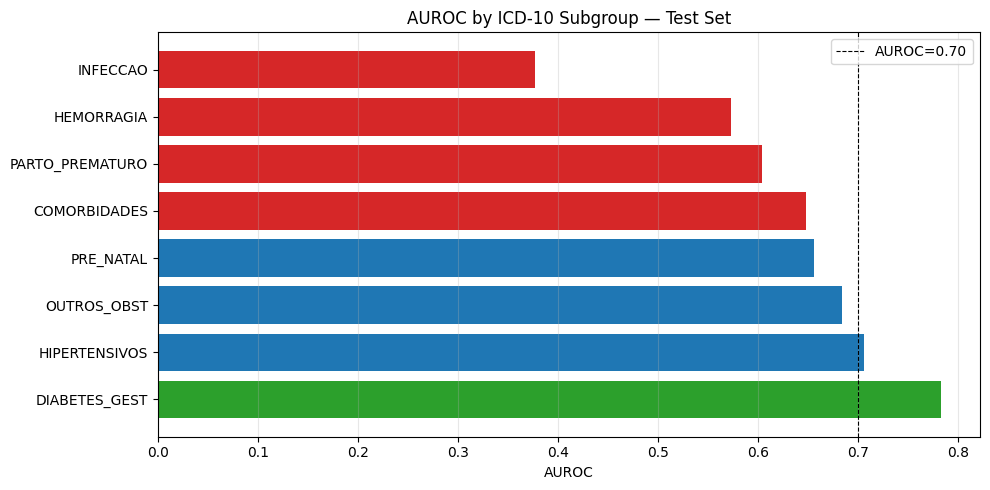

In [5]:
nome_principal = next(n for n in ["M3_XGB","M5_CAT","M4_LGB","M2_RF","M1_LogReg"] if n in modelos_fit)
clf_principal  = modelos_fit[nome_principal]
prob_test_all  = _predict_proba(nome_principal, clf_principal, X_test, X_test_t)
df_test_eval   = df_test.copy()
df_test_eval["prob_pred"] = prob_test_all

df_test_eval["segmento"] = df_test_eval["cd_cid"].apply(segmento_cid)



rows_subgrupo = []
for segmento in df_test_eval["segmento"].unique():
    mask = df_test_eval["segmento"] == segmento
    sub  = df_test_eval[mask]
    if sub["y_retorno_30d"].sum() < 5:
        continue
    m = avaliar(sub["y_retorno_30d"].values, sub["prob_pred"].values, n_boot=500)
    rows_subgrupo.append({
        "segmento"  : segmento,
        "n"             : len(sub),
        "n_retorno_30d" : int(sub["y_retorno_30d"].sum()),
        "prev_pct"      : round(sub["y_retorno_30d"].mean() * 100, 2),
        "auroc"         : round(m.get("auroc", float("nan")), 4),
        "auprc"         : round(m.get("auprc", float("nan")), 4),
    })

tab_subgrupo = pd.DataFrame(rows_subgrupo).sort_values("auroc", ascending=False)
print("\nDesempenho por Subgrupo CID (teste):")
print(tab_subgrupo.to_string(index=False))
tab_subgrupo.to_csv(OUT_DIR / "subgrupo_cid_teste.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
cores_sub = ["#d62728" if a < 0.65 else "#2ca02c" if a > 0.75 else "#1f77b4"
             for a in tab_subgrupo["auroc"]]
ax.barh(tab_subgrupo["segmento"], tab_subgrupo["auroc"], color=cores_sub)
ax.axvline(0.70, color="black", ls="--", lw=0.8, label="AUROC=0.70")
ax.set_xlabel(T["auroc_lbl"]); ax.set_title(T["subgrupo_title"])
ax.legend(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "05_subgrupo_cid_auroc.png", dpi=150)
plt.show()

## 13b. Análise de Fairness por Faixa Etária

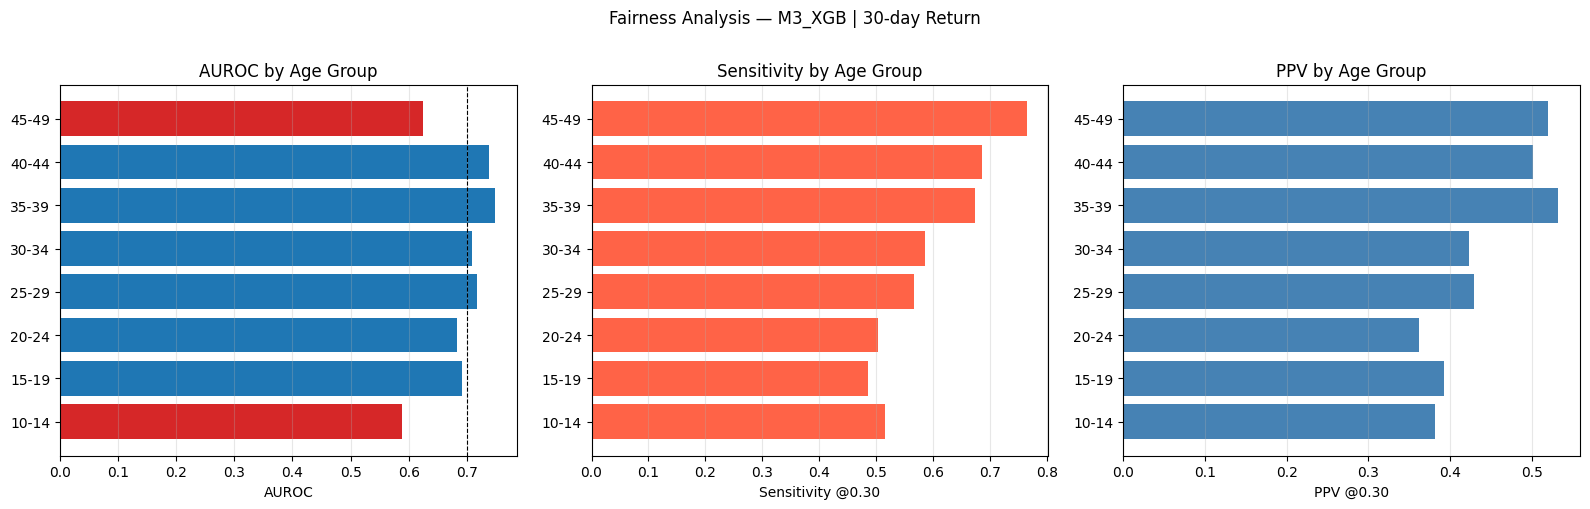

In [6]:
print("\n" + "=" * 70)
print("FAIRNESS — Desempenho por Faixa Etária (teste)")
print("=" * 70)

thr_principal = threshold_youden_por_modelo.get(nome_principal, 0.30)

rows_fair = []
for fx in sorted(df_test["faixa_etaria"].dropna().unique(), key=str):
    mask_fx = (df_test["faixa_etaria"].astype(str) == str(fx))
    y_fx = y_test[mask_fx.values]
    n_fx = len(y_fx)
    n_pos = int(y_fx.sum())
    prev_fx = y_fx.mean() * 100 if n_fx > 0 else 0

    if n_pos < 5 or n_pos == n_fx:
        rows_fair.append({
            "faixa_etaria": fx, "n": n_fx, "n_retorno": n_pos,
            "prevalencia_pct": round(prev_fx, 2),
            "auroc": np.nan, "auprc": np.nan,
            "sens_030": np.nan, "spec_030": np.nan, "ppv_030": np.nan,
        })
        continue

    prob_fx = _predict_proba(nome_principal, clf_principal,
                              X_test[mask_fx.values], X_test_t[mask_fx.values])
    try:
        auroc_fx = roc_auc_score(y_fx, prob_fx)
        auprc_fx = average_precision_score(y_fx, prob_fx)
    except Exception:
        auroc_fx, auprc_fx = np.nan, np.nan

    y_pred_fx = (prob_fx >= 0.30).astype(int)
    tp = ((y_fx == 1) & (y_pred_fx == 1)).sum()
    tn = ((y_fx == 0) & (y_pred_fx == 0)).sum()
    fp = ((y_fx == 0) & (y_pred_fx == 1)).sum()
    fn = ((y_fx == 1) & (y_pred_fx == 0)).sum()

    rows_fair.append({
        "faixa_etaria": fx, "n": n_fx, "n_retorno": n_pos,
        "prevalencia_pct": round(prev_fx, 2),
        "auroc": round(auroc_fx, 4) if not np.isnan(auroc_fx) else np.nan,
        "auprc": round(auprc_fx, 4) if not np.isnan(auprc_fx) else np.nan,
        "sens_030": round(tp / (tp + fn + 1e-9), 4),
        "spec_030": round(tn / (tn + fp + 1e-9), 4),
        "ppv_030": round(tp / (tp + fp + 1e-9), 4),
    })

tab_fair = pd.DataFrame(rows_fair)
print(tab_fair.to_string(index=False))
tab_fair.to_csv(OUT_DIR / "fairness_faixa_etaria.csv", index=False)

fig_fair, axes_fair = plt.subplots(1, 3, figsize=(16, 5))
tab_plot = tab_fair.dropna(subset=["auroc"])
if len(tab_plot) > 0:
    ax = axes_fair[0]
    cores_fair = ["#d62728" if a < 0.65 else "#2ca02c" if a > 0.75 else "#1f77b4"
                  for a in tab_plot["auroc"]]
    ax.barh(tab_plot["faixa_etaria"].astype(str), tab_plot["auroc"], color=cores_fair)
    ax.axvline(0.70, color="black", ls="--", lw=0.8)
    ax.set_xlabel(T["auroc_lbl"]); ax.set_title(T["faixa_auroc_title"]); ax.grid(axis="x", alpha=0.3)

    ax = axes_fair[1]
    ax.barh(tab_plot["faixa_etaria"].astype(str), tab_plot["sens_030"], color="tomato")
    ax.set_xlabel(T["faixa_sens_title"]); ax.set_title(T["faixa_sens_ylabel"]); ax.grid(axis="x", alpha=0.3)

    ax = axes_fair[2]
    ax.barh(tab_plot["faixa_etaria"].astype(str), tab_plot["ppv_030"], color="steelblue")
    ax.set_xlabel(T["faixa_ppv_title"]); ax.set_title(T["faixa_ppv_ylabel"]); ax.grid(axis="x", alpha=0.3)

plt.suptitle(T["faixa_suptitle_fmt"].format(nome=nome_principal), fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / "05b_fairness_faixa_etaria.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close()

## 13c. Fairness por Ano (Drift Temporal)

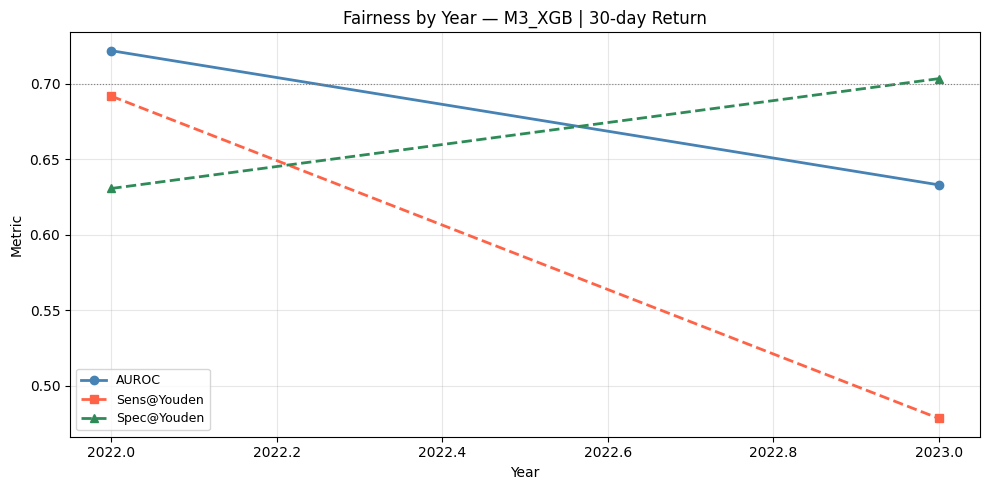

In [7]:
print("\n" + "=" * 70)
print("FAIRNESS — Desempenho por Ano (drift temporal, conjunto de teste)")
print("=" * 70)

rows_fair_ano = []
for ano_val in sorted(df_test["ano"].dropna().unique()):
    mask_ano = (df_test["ano"] == ano_val).values
    y_ano = y_test[mask_ano]
    n_ano = len(y_ano)
    n_pos_ano = int(y_ano.sum())
    if n_pos_ano < 5 or n_pos_ano == n_ano:
        continue
    prob_ano = _predict_proba(nome_principal, clf_principal,
                               X_test[mask_ano], X_test_t[mask_ano])
    try:
        auroc_ano = roc_auc_score(y_ano, prob_ano)
        thr_youden_ano = youden_threshold(y_ano, prob_ano)
        y_pred_ano_youd = (prob_ano >= thr_youden_ano).astype(int)
        tp_a = ((y_ano == 1) & (y_pred_ano_youd == 1)).sum()
        tn_a = ((y_ano == 0) & (y_pred_ano_youd == 0)).sum()
        fp_a = ((y_ano == 0) & (y_pred_ano_youd == 1)).sum()
        fn_a = ((y_ano == 1) & (y_pred_ano_youd == 0)).sum()
        sens_a = tp_a / (tp_a + fn_a + 1e-9)
        spec_a = tn_a / (tn_a + fp_a + 1e-9)
    except Exception:
        auroc_ano, sens_a, spec_a, thr_youden_ano = np.nan, np.nan, np.nan, np.nan

    rows_fair_ano.append({
        "ano": int(ano_val), "n": n_ano, "n_retorno": n_pos_ano,
        "prev_pct": round(y_ano.mean() * 100, 2),
        "auroc": round(auroc_ano, 4) if not np.isnan(auroc_ano) else np.nan,
        "sens_youden": round(sens_a, 4) if not np.isnan(sens_a) else np.nan,
        "spec_youden": round(spec_a, 4) if not np.isnan(spec_a) else np.nan,
        "threshold_youden": round(thr_youden_ano, 4) if not np.isnan(thr_youden_ano) else np.nan,
    })
    print(f"  Ano {int(ano_val)}: n={n_ano}  n_pos={n_pos_ano}  AUROC={auroc_ano:.4f}")

tab_fair_ano = pd.DataFrame(rows_fair_ano)
tab_fair_ano.to_csv(OUT_DIR / "fairness_por_ano.csv", index=False)

if len(tab_fair_ano) > 0:
    fig_ano, ax_ano = plt.subplots(figsize=(10, 5))
    ax_ano.plot(tab_fair_ano["ano"], tab_fair_ano["auroc"], "o-", color="steelblue", lw=2, label=T["drift_lbl_auroc"])
    ax_ano.plot(tab_fair_ano["ano"], tab_fair_ano["sens_youden"], "s--", color="tomato", lw=2, label=T["drift_lbl_sens"])
    ax_ano.plot(tab_fair_ano["ano"], tab_fair_ano["spec_youden"], "^--", color="seagreen", lw=2, label=T["drift_lbl_spec"])
    ax_ano.axhline(0.70, color="gray", ls=":", lw=0.8)
    ax_ano.set_xlabel(T["drift_xlabel"]); ax_ano.set_ylabel(T["drift_ylabel"])
    ax_ano.set_title(T["drift_suptitle_fmt"].format(nome=nome_principal))
    ax_ano.legend(fontsize=9); ax_ano.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "05c_fairness_por_ano.png", dpi=150)
    plt.show(); plt.close()
    print("  Gerado: plots/05c_fairness_por_ano.png")

## 13d. Fairness por Tipo de Atendimento

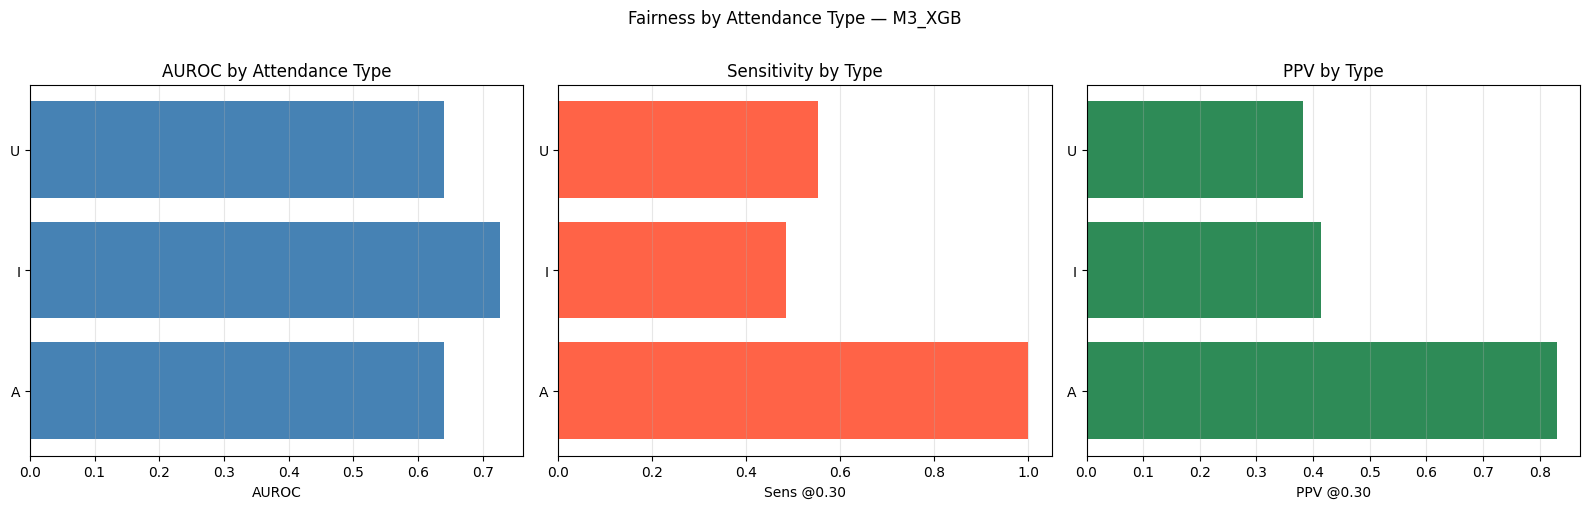

In [8]:
print("\n" + "=" * 70)
print("FAIRNESS — Desempenho por Tipo de Atendimento (teste)")
print("=" * 70)

rows_fair_tp = []
if "tp_atendimento" in df_test.columns:
    for tp_val in sorted(df_test["tp_atendimento"].dropna().unique(), key=str):
        mask_tp = (df_test["tp_atendimento"].astype(str) == str(tp_val)).values
        y_tp = y_test[mask_tp]
        n_tp = len(y_tp)
        n_pos_tp = int(y_tp.sum())
        if n_pos_tp < 5 or n_pos_tp == n_tp:
            continue
        prob_tp = _predict_proba(nome_principal, clf_principal,
                                  X_test[mask_tp], X_test_t[mask_tp])
        try:
            auroc_tp = roc_auc_score(y_tp, prob_tp)
            auprc_tp = average_precision_score(y_tp, prob_tp)
            y_pred_tp = (prob_tp >= 0.30).astype(int)
            tp_ = ((y_tp == 1) & (y_pred_tp == 1)).sum()
            tn_ = ((y_tp == 0) & (y_pred_tp == 0)).sum()
            fp_ = ((y_tp == 0) & (y_pred_tp == 1)).sum()
            fn_ = ((y_tp == 1) & (y_pred_tp == 0)).sum()
            sens_tp = tp_ / (tp_ + fn_ + 1e-9)
            spec_tp = tn_ / (tn_ + fp_ + 1e-9)
            ppv_tp  = tp_ / (tp_ + fp_ + 1e-9)
        except Exception:
            auroc_tp, auprc_tp, sens_tp, spec_tp, ppv_tp = np.nan, np.nan, np.nan, np.nan, np.nan

        rows_fair_tp.append({
            "tp_atendimento": tp_val, "n": n_tp, "n_retorno": n_pos_tp,
            "prev_pct": round(y_tp.mean() * 100, 2),
            "auroc": round(auroc_tp, 4) if not np.isnan(auroc_tp) else np.nan,
            "auprc": round(auprc_tp, 4) if not np.isnan(auprc_tp) else np.nan,
            "sens_030": round(sens_tp, 4) if not np.isnan(sens_tp) else np.nan,
            "spec_030": round(spec_tp, 4) if not np.isnan(spec_tp) else np.nan,
            "ppv_030": round(ppv_tp, 4) if not np.isnan(ppv_tp) else np.nan,
        })
        print(f"  tp={tp_val}: n={n_tp}  AUROC={auroc_tp:.4f}  Sens={sens_tp:.4f}  Spec={spec_tp:.4f}")

tab_fair_tp = pd.DataFrame(rows_fair_tp)
tab_fair_tp.to_csv(OUT_DIR / "fairness_tipo_atendimento.csv", index=False)

if len(tab_fair_tp) > 0:
    fig_tp, axes_tp = plt.subplots(1, 3, figsize=(16, 5))
    tab_tp_plot = tab_fair_tp.dropna(subset=["auroc"])
    if len(tab_tp_plot) > 0:
        axes_tp[0].barh(tab_tp_plot["tp_atendimento"].astype(str), tab_tp_plot["auroc"], color="steelblue")
        axes_tp[0].set_xlabel(T["auroc_lbl"]); axes_tp[0].set_title(T["tipo_auroc_title"]); axes_tp[0].grid(axis="x", alpha=0.3)
        axes_tp[1].barh(tab_tp_plot["tp_atendimento"].astype(str), tab_tp_plot["sens_030"], color="tomato")
        axes_tp[1].set_xlabel(T["tipo_sens_ylabel"]); axes_tp[1].set_title(T["tipo_sens_title"]); axes_tp[1].grid(axis="x", alpha=0.3)
        axes_tp[2].barh(tab_tp_plot["tp_atendimento"].astype(str), tab_tp_plot["ppv_030"], color="seagreen")
        axes_tp[2].set_xlabel(T["tipo_ppv_ylabel"]); axes_tp[2].set_title(T["tipo_ppv_title"]); axes_tp[2].grid(axis="x", alpha=0.3)
    plt.suptitle(T["tipo_suptitle_fmt"].format(nome=nome_principal), fontsize=12, y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "05d_fairness_tipo_atendimento.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: plots/05d_fairness_tipo_atendimento.png")

## 13e. Fairness por Paridade Obstétrica

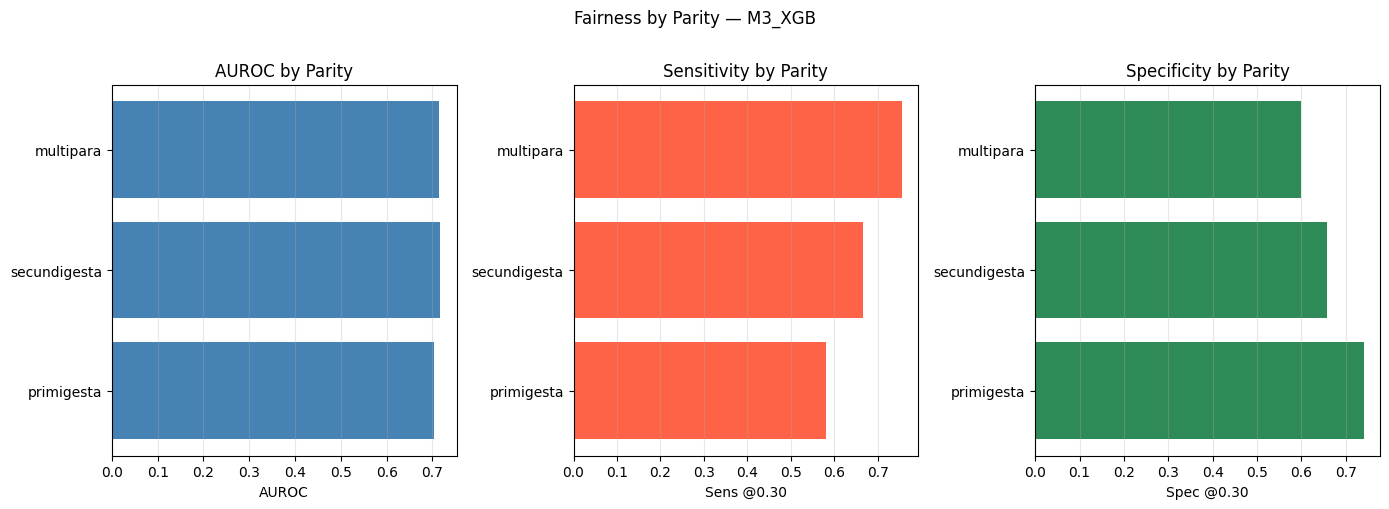

In [9]:
print("\n" + "=" * 70)
print("FAIRNESS — Desempenho por Paridade (primigesta / secundigesta / multipara)")
print("=" * 70)

rows_fair_par = []
if "G_obs" in df_test.columns:
    g_vals = pd.to_numeric(df_test["G_obs"], errors="coerce")
    parity_groups = {
        "primigesta":    (g_vals == 1),
        "secundigesta":  (g_vals == 2),
        "multipara":     (g_vals >= 3),
    }
    for grp_name, mask_grp_series in parity_groups.items():
        mask_grp = mask_grp_series.fillna(False).values
        y_grp = y_test[mask_grp]
        n_grp = len(y_grp)
        n_pos_grp = int(y_grp.sum())
        if n_pos_grp < 5 or n_pos_grp == n_grp:
            print(f"  {grp_name}: pulado (n_eventos={n_pos_grp})")
            continue
        prob_grp = _predict_proba(nome_principal, clf_principal,
                                   X_test[mask_grp], X_test_t[mask_grp])
        try:
            auroc_grp = roc_auc_score(y_grp, prob_grp)
            y_pred_grp = (prob_grp >= 0.30).astype(int)
            tp_g = ((y_grp == 1) & (y_pred_grp == 1)).sum()
            tn_g = ((y_grp == 0) & (y_pred_grp == 0)).sum()
            fp_g = ((y_grp == 0) & (y_pred_grp == 1)).sum()
            fn_g = ((y_grp == 1) & (y_pred_grp == 0)).sum()
            sens_grp = tp_g / (tp_g + fn_g + 1e-9)
            spec_grp = tn_g / (tn_g + fp_g + 1e-9)
        except Exception:
            auroc_grp, sens_grp, spec_grp = np.nan, np.nan, np.nan

        rows_fair_par.append({
            "paridade": grp_name, "n": n_grp, "n_retorno": n_pos_grp,
            "prev_pct": round(y_grp.mean() * 100, 2),
            "auroc": round(auroc_grp, 4) if not np.isnan(auroc_grp) else np.nan,
            "sens_030": round(sens_grp, 4) if not np.isnan(sens_grp) else np.nan,
            "spec_030": round(spec_grp, 4) if not np.isnan(spec_grp) else np.nan,
        })
        print(f"  {grp_name}: n={n_grp}  AUROC={auroc_grp:.4f}  Sens={sens_grp:.4f}  Spec={spec_grp:.4f}")

tab_fair_par = pd.DataFrame(rows_fair_par)
tab_fair_par.to_csv(OUT_DIR / "fairness_paridade.csv", index=False)

if len(tab_fair_par) > 0:
    fig_par, axes_par = plt.subplots(1, 3, figsize=(14, 5))
    tab_par_plot = tab_fair_par.dropna(subset=["auroc"])
    if len(tab_par_plot) > 0:
        axes_par[0].barh(tab_par_plot["paridade"].astype(str), tab_par_plot["auroc"], color="steelblue")
        axes_par[0].set_xlabel(T["auroc_lbl"]); axes_par[0].set_title(T["par_auroc_title"]); axes_par[0].grid(axis="x", alpha=0.3)
        axes_par[1].barh(tab_par_plot["paridade"].astype(str), tab_par_plot["sens_030"], color="tomato")
        axes_par[1].set_xlabel(T["par_sens_ylabel"]); axes_par[1].set_title(T["par_sens_title"]); axes_par[1].grid(axis="x", alpha=0.3)
        axes_par[2].barh(tab_par_plot["paridade"].astype(str), tab_par_plot["spec_030"], color="seagreen")
        axes_par[2].set_xlabel(T["par_spec_ylabel"]); axes_par[2].set_title(T["par_spec_title"]); axes_par[2].grid(axis="x", alpha=0.3)
    plt.suptitle(T["par_suptitle_fmt"].format(nome=nome_principal), fontsize=12, y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "05e_fairness_paridade.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: plots/05e_fairness_paridade.png")

## 14. Curvas de Aprendizado

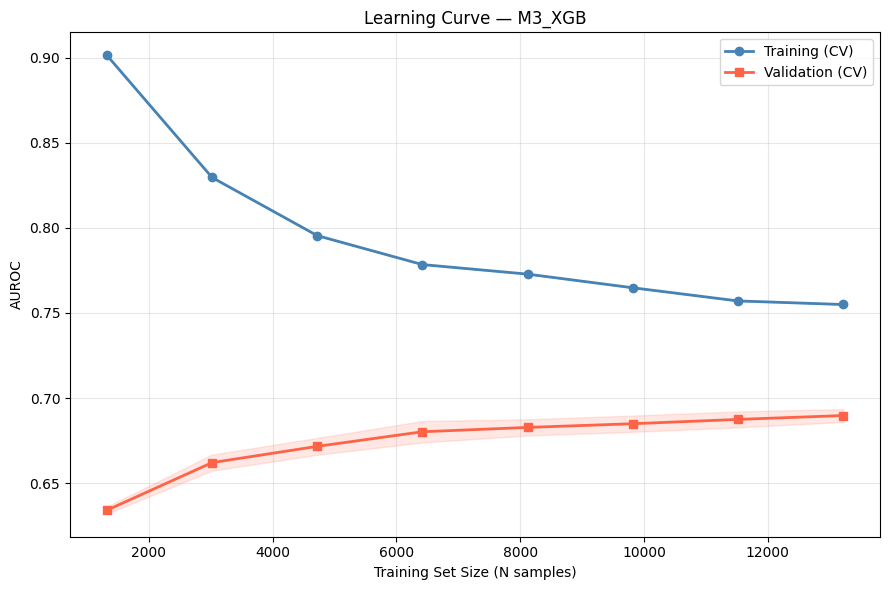

In [10]:
from sklearn.model_selection import learning_curve as sk_learning_curve, TimeSeriesSplit

print("\n" + "=" * 70)
print("CURVAS DE APRENDIZADO — Modelo Principal")
print("=" * 70)

nome_lc = next(n for n in ["M3_XGB","M4_LGB","M2_RF","M1_LogReg"] if n in modelos_fit)
clf_lc  = modelos_fit[nome_lc]
print(f"Modelo para learning curve: {nome_lc}")

try:
    train_sizes = np.linspace(0.1, 1.0, 8)
    tscv_lc = TimeSeriesSplit(n_splits=3)

    train_sizes_abs, train_scores, val_scores = sk_learning_curve(
        clf_lc, X_train_t, y_train,
        train_sizes=train_sizes,
        cv=tscv_lc,
        scoring="roc_auc",
        n_jobs=-1,
        verbose=0,
    )

    train_mean = train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    val_mean   = val_scores.mean(axis=1)
    val_std    = val_scores.std(axis=1)

    fig_lc, ax_lc = plt.subplots(figsize=(9, 6))
    ax_lc.plot(train_sizes_abs, train_mean, "o-", color="steelblue", lw=2, label=T["lc_train_lbl"])
    ax_lc.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std,
                        alpha=0.15, color="steelblue")
    ax_lc.plot(train_sizes_abs, val_mean, "s-", color="tomato", lw=2, label=T["lc_valid_lbl"])
    ax_lc.fill_between(train_sizes_abs, val_mean - val_std, val_mean + val_std,
                        alpha=0.15, color="tomato")
    ax_lc.set_xlabel(T["lc_xlabel"])
    ax_lc.set_ylabel(T["lc_ylabel"])
    ax_lc.set_title(T["lc_title_fmt"].format(nome=nome_lc))
    ax_lc.legend(fontsize=10); ax_lc.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "learning_curve.png", dpi=150)
    plt.show(); plt.close()
    print("  Gerado: plots/learning_curve.png")

    lc_df = pd.DataFrame({
        "n_treino": train_sizes_abs,
        "auroc_treino_mean": train_mean,
        "auroc_treino_std": train_std,
        "auroc_val_mean": val_mean,
        "auroc_val_std": val_std,
    })
    lc_df.to_csv(OUT_DIR / "learning_curve_data.csv", index=False)
    print("  Gerado: learning_curve_data.csv")

except Exception as e:
    print(f"  Erro na learning curve: {e}")

## 15. Análise de Drift Temporal

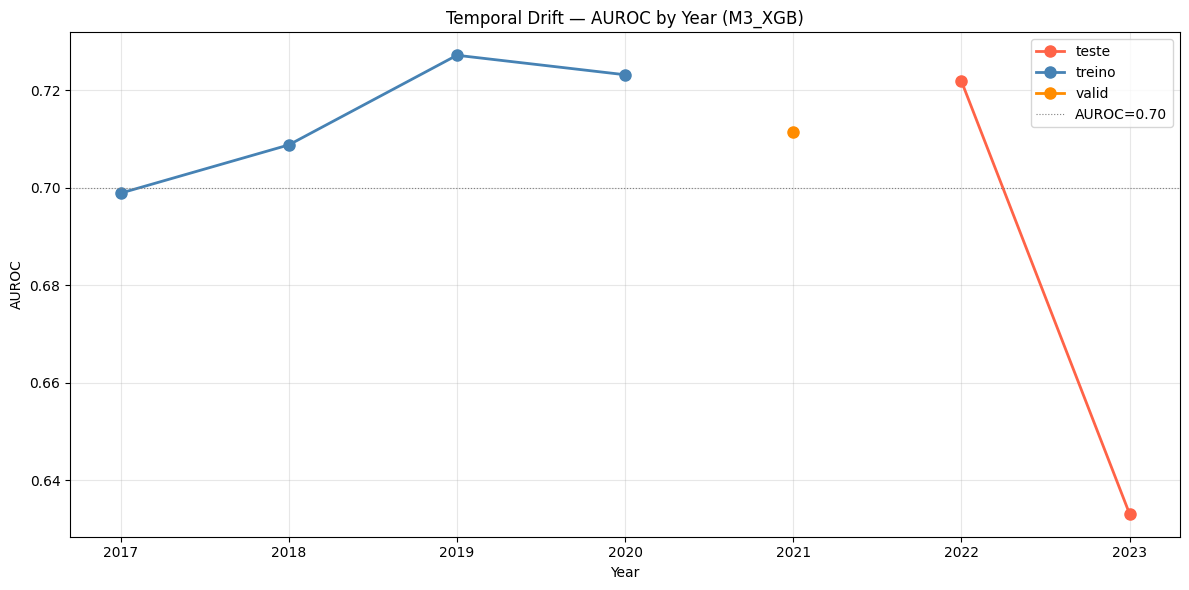

In [11]:
print("\n" + "=" * 70)
print("ANÁLISE DE DRIFT TEMPORAL — AUROC por Ano (treino+valid+teste)")
print("=" * 70)

rows_drift = []
for split_name, split_df_drift, split_Xraw, split_Xt in [
    ("treino", df_train, X_train, X_train_t),
    ("valid",  df_valid, X_valid, X_valid_t),
    ("teste",  df_test,  X_test,  X_test_t),
]:
    for ano_val in sorted(split_df_drift["ano"].dropna().unique()):
        mask_d = (split_df_drift["ano"] == ano_val).values
        y_d = split_df_drift["y_retorno_30d"].values[mask_d]
        n_d = len(y_d)
        n_pos_d = int(y_d.sum())
        if n_pos_d < 5 or n_pos_d == n_d:
            continue
        try:
            prob_d = _predict_proba(nome_principal, clf_principal,
                                     split_Xraw[mask_d], split_Xt[mask_d])
            auroc_d = roc_auc_score(y_d, prob_d)
        except Exception:
            auroc_d = np.nan

        rows_drift.append({
            "split": split_name,
            "ano": int(ano_val),
            "n": n_d,
            "n_pos": n_pos_d,
            "auroc": round(auroc_d, 4) if not np.isnan(auroc_d) else np.nan,
        })
        print(f"  [{split_name}] Ano {int(ano_val)}: n={n_d}  AUROC={auroc_d:.4f}")

tab_drift = pd.DataFrame(rows_drift)
tab_drift.to_csv(OUT_DIR / "drift_temporal_auroc_por_ano.csv", index=False)

if len(tab_drift) > 0:
    fig_drift, ax_drift = plt.subplots(figsize=(12, 6))
    cores_splits = {"treino": "steelblue", "valid": "darkorange", "teste": "tomato"}
    for split_nm, grp in tab_drift.groupby("split"):
        ax_drift.plot(grp["ano"], grp["auroc"], "o-",
                       color=cores_splits.get(split_nm, "gray"),
                       lw=2, label=split_nm, markersize=8)
    ax_drift.axhline(0.70, color="gray", ls=":", lw=0.8, label="AUROC=0.70")
    ax_drift.set_xlabel(T["temporal_xlabel"]); ax_drift.set_ylabel(T["temporal_ylabel"])
    ax_drift.set_title(T["temporal_title_fmt"].format(nome=nome_principal))
    ax_drift.legend(fontsize=10); ax_drift.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "15_drift_temporal_auroc.png", dpi=150)
    plt.show(); plt.close()
    print("  Gerado: plots/15_drift_temporal_auroc.png")

## 13f. Fairness por Raça/Etnia (tp_cor)

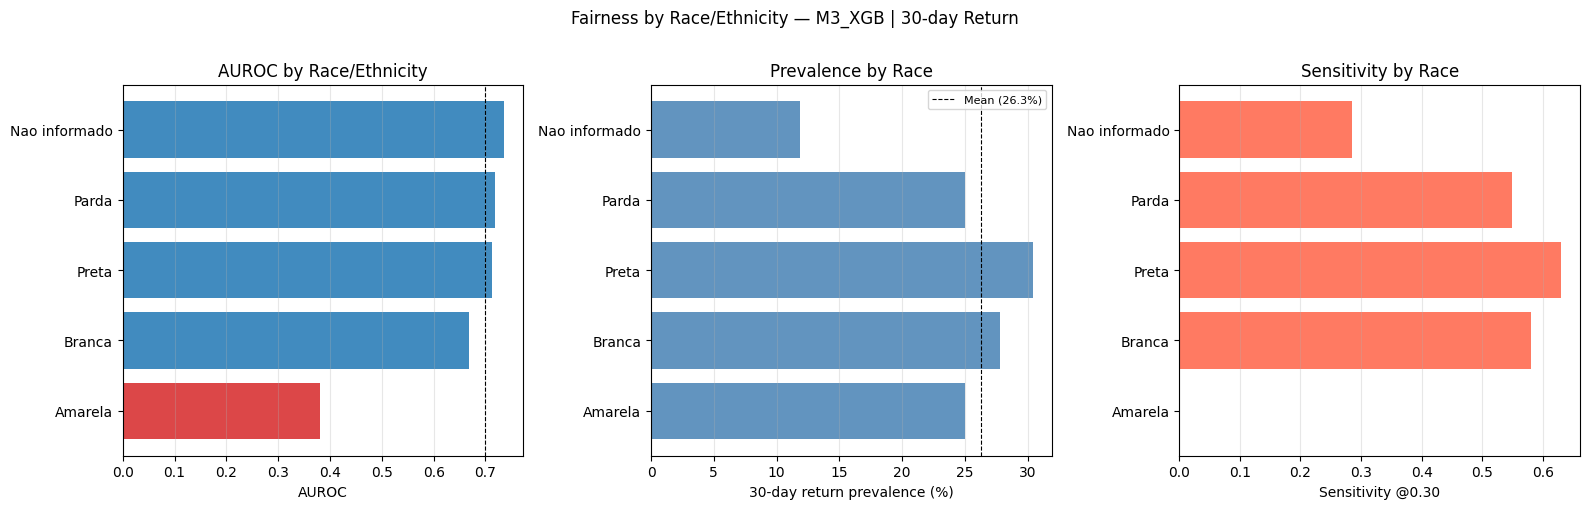

In [12]:
print("\n" + "=" * 70)
print("FAIRNESS — Desempenho por Raça/Etnia (tp_cor)")
print("=" * 70)

cor_map = {"R":"Parda","B":"Branca","P":"Preta","A":"Amarela","I":"Indígena/Ignorada", "S": "Nao informado"}
rows_fair_cor = []

if "tp_cor" in df_test.columns:
    for cor_val in sorted(df_test["tp_cor"].dropna().unique(), key=str):
        mask_cor = (df_test["tp_cor"].astype(str) == str(cor_val)).values
        y_cor = y_test[mask_cor]; n_cor = len(y_cor); n_pos_cor = int(y_cor.sum())
        if n_pos_cor < 5 or n_pos_cor == n_cor:
            continue
        prob_cor = _predict_proba(nome_principal, clf_principal,
                                   X_test[mask_cor], X_test_t[mask_cor])
        try:
            auroc_cor = roc_auc_score(y_cor, prob_cor)
            auprc_cor = average_precision_score(y_cor, prob_cor)
            y_pred_cor = (prob_cor >= 0.30).astype(int)
            tp_ = ((y_cor==1)&(y_pred_cor==1)).sum()
            tn_ = ((y_cor==0)&(y_pred_cor==0)).sum()
            fp_ = ((y_cor==0)&(y_pred_cor==1)).sum()
            fn_ = ((y_cor==1)&(y_pred_cor==0)).sum()
            sens_cor = tp_ / (tp_ + fn_ + 1e-9)
            spec_cor = tn_ / (tn_ + fp_ + 1e-9)
            ppv_cor  = tp_ / (tp_ + fp_ + 1e-9)
        except Exception:
            auroc_cor=auprc_cor=sens_cor=spec_cor=ppv_cor=np.nan

        lbl = cor_map.get(cor_val, cor_val)
        rows_fair_cor.append({
            "tp_cor":cor_val,"raca_lbl":lbl,"n":n_cor,"n_retorno":n_pos_cor,
            "prev_pct":round(y_cor.mean()*100,2),
            "auroc":   round(auroc_cor,4) if not np.isnan(auroc_cor) else np.nan,
            "sens_030":round(sens_cor,4)  if not np.isnan(sens_cor)  else np.nan,
            "spec_030":round(spec_cor,4)  if not np.isnan(spec_cor)  else np.nan,
            "ppv_030": round(ppv_cor,4)   if not np.isnan(ppv_cor)   else np.nan,
        })
        print(f"  {lbl:<22}: n={n_cor:>6,}  prev={y_cor.mean()*100:.1f}%  "
              f"AUROC={auroc_cor:.4f}  Sens={sens_cor:.4f}")

    tab_fair_cor = pd.DataFrame(rows_fair_cor)
    tab_fair_cor.to_csv(OUT_DIR / "fairness_raca_etnia.csv", index=False)

    if len(tab_fair_cor) > 0:
        tab_cor_plot = tab_fair_cor.dropna(subset=["auroc"])
        if len(tab_cor_plot) > 0:
            fig_cor, axes_cor = plt.subplots(1, 3, figsize=(16, 5))
            cores_auroc = ["#d62728" if a<0.65 else "#2ca02c" if a>0.75 else "#1f77b4"
                           for a in tab_cor_plot["auroc"]]
            axes_cor[0].barh(tab_cor_plot["raca_lbl"].astype(str), tab_cor_plot["auroc"],
                             color=cores_auroc, alpha=0.85)
            axes_cor[0].axvline(0.70, color="black", ls="--", lw=0.8)
            axes_cor[0].set_xlabel(T["auroc_lbl"]); axes_cor[0].set_title(T["raca_auroc_title"])
            axes_cor[0].grid(axis="x", alpha=0.3)

            axes_cor[1].barh(tab_cor_plot["raca_lbl"].astype(str), tab_cor_plot["prev_pct"],
                             color="steelblue", alpha=0.85)
            axes_cor[1].axvline(y_test.mean()*100, color="black", ls="--", lw=0.8,
                                label=T["raca_prev_lbl_fmt"].format(pct=y_test.mean()*100))
            axes_cor[1].set_xlabel(T["raca_prev_title"]); axes_cor[1].set_title(T["raca_prev_ylabel"])
            axes_cor[1].legend(fontsize=8); axes_cor[1].grid(axis="x", alpha=0.3)

            axes_cor[2].barh(tab_cor_plot["raca_lbl"].astype(str), tab_cor_plot["sens_030"],
                             color="tomato", alpha=0.85)
            axes_cor[2].set_xlabel(T["raca_sens_ylabel"]); axes_cor[2].set_title(T["raca_sens_title"])
            axes_cor[2].grid(axis="x", alpha=0.3)

            plt.suptitle(T["raca_suptitle_fmt"].format(nome=nome_principal),
                         fontsize=12, y=1.01)
            plt.tight_layout()
            plt.savefig(PLOT_DIR / "05f_fairness_raca_etnia.png", dpi=150, bbox_inches="tight")
            plt.show(); plt.close()
            print("  Gerado: plots/05f_fairness_raca_etnia.png")
else:
    print("  tp_cor ausente — re-execute 03.1 para incluir raça/etnia nas features.")

print(f"\n[03.5] Concluído. Outputs: {OUT_DIR}")